# Supervised PatchTST baseline

PatchTST cuts each KPI channel into overlapping patches and reads them with a small Transformer, one channel at a time. A linear head joins the 16 channel summaries to classify the window. The model is trained from random initialization for detection and for the ten synthetic fault categories.

This notebook reads saved runs only; it does not retrain. The release has unresolved recording reviews, so all numbers are provisional. Settings were chosen on development data; the test split is untouched.

Command-line equivalents:

- `uv run python -m clauseguard.cli.patchtst train --release-dir data/scenarios/release --xgboost-reference artifacts/experiments/xgboost-full-data-2026-10-19 --output-dir artifacts/experiments/patchtst-full-data-2026-11-05 --allow-exploratory`
- `uv run python -m clauseguard.cli.patchtst compare --experiment random_forest=artifacts/experiments/rf-all-data-provisional-2026-10-19 --experiment xgboost=artifacts/experiments/xgboost-full-data-2026-10-19 --experiment timesnet=artifacts/experiments/timesnet-v3-full --experiment patchtst=artifacts/experiments/patchtst-full-data-2026-11-05 --output-dir artifacts/experiments/task-3-11-comparison-2026-11-05`
- `uv run python -m clauseguard.cli.patchtst predict --release-dir data/scenarios/release --allow-exploratory --model-run-dir artifacts/experiments/patchtst-full-data-2026-11-05/detection/config-2-seed-42 --split dev --output-dir NEW_DIR` (replay a saved model without refitting)

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from clauseguard.baselines.artifacts import load_run
from clauseguard.datasets.contracts import CATEGORY_LABELS, LABEL_MAPPINGS

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents)
            if (path / "data/scenarios/release/release.json").exists())
os.chdir(ROOT)
OUTPUT_DIR = Path("artifacts/experiments/patchtst-full-data-2026-11-05")
COMPARISON_DIR = Path("artifacts/experiments/task-3-11-comparison-2026-11-05")
SUMMARY = json.loads((OUTPUT_DIR / "selection.json").read_text())
pd.DataFrame([{"task": task, "selected": row["selected_configuration"],
               "dev macro-F1 (seeds)": [round(s["dev_macro_f1"], 3) for s in row["selected_seeds"]],
               "mean": round(row["dev_macro_f1_mean"], 3), "train windows": row["train_windows"],
               "dev windows": row["dev_windows"]} for task, row in SUMMARY["tasks"].items()])

,task,selected,dev macro-F1 (seeds),mean,train windows,dev windows
0,category,"{'learning_rate': 0.001, 'patch_length': 16}","[0.155, 0.138, 0.185]",0.159,563,177
1,detection,"{'learning_rate': 0.001, 'patch_length': 16}","[0.839, 0.815, 0.768]",0.807,19089,6590


## Four settings with seed 42

Each setting trains until the unweighted development loss stops improving for 10 epochs; the best epoch is restored before scoring.

In [2]:
pd.DataFrame([{"task": task, **trial["configuration"], "dev macro-F1": round(trial["dev_macro_f1"], 3),
               "best epoch": trial["best_epoch"], "best dev loss": round(trial["best_dev_loss"], 4),
               "hit epoch cap": trial["hit_epoch_cap"]}
              for task, row in SUMMARY["tasks"].items() for trial in row["trials"]])

,task,learning_rate,patch_length,dev macro-F1,best epoch,best dev loss,hit epoch cap
0,category,0.0010,8,0.125,1,2.5068,False
1,category,0.0003,8,0.064,0,2.3853,False
2,category,0.0010,16,0.155,0,2.3629,False
3,category,0.0003,16,0.099,0,2.2791,False
4,detection,0.0010,8,0.807,2,0.1612,False
5,detection,0.0003,8,0.810,2,0.1610,False
6,detection,0.0010,16,0.839,15,0.1481,False
7,detection,0.0003,16,0.805,2,0.1732,False


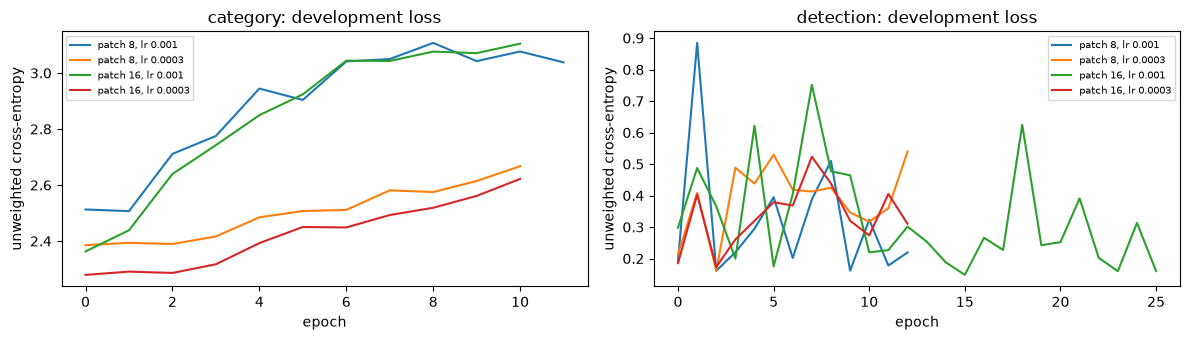

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for axis, (task, row) in zip(axes, SUMMARY["tasks"].items(), strict=True):
    for trial in row["trials"]:
        history = load_run(OUTPUT_DIR / trial["run"])["metadata"].configuration["history"]
        label = f"patch {trial['configuration']['patch_length']}, lr {trial['configuration']['learning_rate']}"
        axis.plot([h["dev_loss"] for h in history], label=label)
    axis.set(title=f"{task}: development loss", xlabel="epoch", ylabel="unweighted cross-entropy")
    axis.legend(fontsize=7)
fig.tight_layout()

## Comparison with earlier baselines on identical development windows

In [4]:
print((COMPARISON_DIR / "comparison.md").read_text())

# KPI model comparison (development split only)

## Detection

Release `f3bd4d46`, status `provisional_exploratory`, dev cohort `d52511bb`.

| Model | Dev macro-F1 | Median | Seeds | Accuracy | False alarms | Missed faults | Failed predictions | Fit s | Predict s | Peak RSS GB | Size MB |
|---|---|---|---|---|---|---|---|---|---|---|---|
| random_forest | 0.661 ± 0.005 | 0.663 | 0.663 / 0.666 / 0.654 | 0.958 / 0.959 / 0.956 | 83 / 76 / 95 | 195 / 195 / 197 | 0 | 10.9 | 1.42 | 2.75 | 1.67 |
| xgboost | 0.882 ± 0.000 | 0.882 | 0.882 / 0.882 / 0.882 | 0.983 / 0.983 / 0.983 | 26 / 26 / 26 | 83 / 83 / 83 | 0 | 2.4 | 1.48 | 2.68 | 0.26 |
| timesnet | 0.616 ± 0.032 | 0.632 | 0.571 / 0.645 / 0.632 | 0.822 / 0.886 / 0.916 | 1094 / 684 / 407 | 80 / 65 / 146 | 0 | 313.8 | 2.01 | 3.99 | 1.16 |
| patchtst | 0.807 ± 0.029 | 0.815 | 0.839 / 0.815 / 0.768 | 0.977 / 0.978 / 0.971 | 56 / 8 / 41 | 98 / 138 / 151 | 0 | 685.9 | 4.98 | 1.29 | 0.09 |

Selected settings:

- random_forest: `{"max_depth": null,

,patchtst,random_forest,timesnet,xgboost
Detection F1 per class (mean over seeds),,,,
normal,0.987,0.978,0.931,0.991
abnormal,0.628,0.344,0.301,0.773


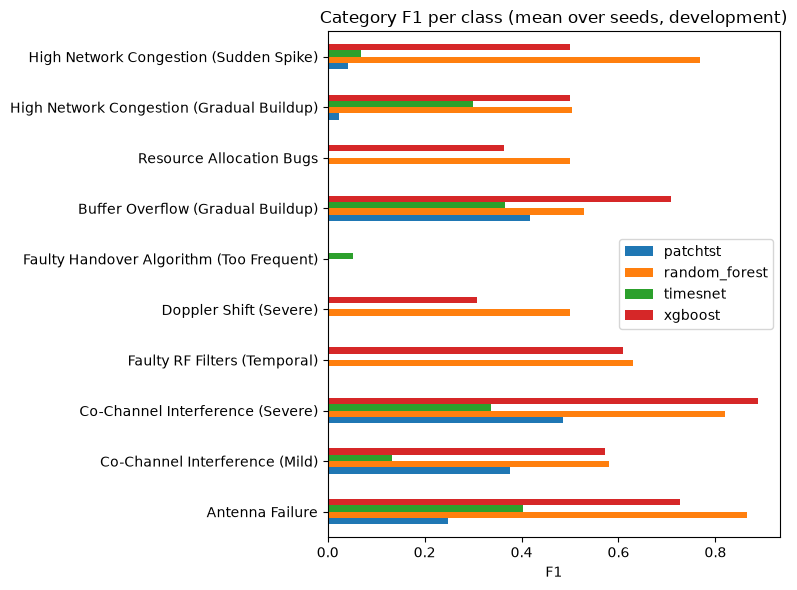

In [5]:
reports = {report["task"]: report for report in json.loads((COMPARISON_DIR / "comparison.json").read_text())}
detection = pd.DataFrame({name: model["per_class_f1_mean"] for name, model in reports["detection"]["models"].items()})
detection.index = [{v: k for k, v in LABEL_MAPPINGS["detection"].items()}[int(label)] for label in detection.index]
display(detection.round(3).rename_axis("Detection F1 per class (mean over seeds)"))
frame = pd.DataFrame({name: model["per_class_f1_mean"] for name, model in reports["category"]["models"].items()})
frame.index = [CATEGORY_LABELS[int(label)] for label in frame.index]
ax = frame.plot.barh(figsize=(8, 6))
ax.set(title="Category F1 per class (mean over seeds, development)", xlabel="F1")
plt.tight_layout()

## Reload check

Every saved run reloads its weights and must reproduce the same predictions; the largest logit difference after reload is recorded.

In [6]:
pd.DataFrame([{"task": task, "run": seed["run"],
               "reload max |logit diff|": load_run(OUTPUT_DIR / seed["run"])["metadata"].configuration["reload_max_abs_logit_diff"],
               "parameters": load_run(OUTPUT_DIR / seed["run"])["metadata"].configuration["parameter_count"],
               "device": load_run(OUTPUT_DIR / seed["run"])["metadata"].configuration["device"]}
              for task, row in SUMMARY["tasks"].items() for seed in row["selected_seeds"]])

,task,run,reload max |logit diff|,parameters,device
0,category,category/config-2-seed-42,0.0,23244,cpu
1,category,category/selected-seed-43,0.0,23244,cpu
2,category,category/selected-seed-44,0.0,23244,cpu
3,detection,detection/config-2-seed-42,0.0,19140,cpu
4,detection,detection/selected-seed-43,0.0,19140,cpu
5,detection,detection/selected-seed-44,0.0,19140,cpu


## Replay with the CLI

The `predict` command reloads the selected detection checkpoint and its saved scaler, scores the development split without refitting, and writes to a new temporary directory. Its predictions must equal the saved run's.

In [7]:
import contextlib
import io
import tempfile

from clauseguard.cli.patchtst import main as patchtst_cli

RUN_DIR = OUTPUT_DIR / SUMMARY["tasks"]["detection"]["selected_seeds"][0]["run"]
with tempfile.TemporaryDirectory() as scratch, contextlib.redirect_stdout(io.StringIO()):
    replay_dir = Path(scratch) / "replay"
    code = patchtst_cli(["predict", "--release-dir", "data/scenarios/release", "--allow-exploratory",
                         "--model-run-dir", str(RUN_DIR), "--split", "dev", "--bootstrap-replicates", "0",
                         "--output-dir", str(replay_dir)])
    replay = load_run(replay_dir)
saved = load_run(RUN_DIR)
assert code == 0
same = ([(p.scenario_id, p.predicted_label) for p in saved["predictions"]]
        == [(p.scenario_id, p.predicted_label) for p in replay["predictions"]])
{"run": str(RUN_DIR), "windows": len(replay["predictions"]), "identical predictions": same,
 "saved macro-F1": round(saved["metrics"]["macro_f1"], 4), "replay macro-F1": round(replay["metrics"]["macro_f1"], 4)}

{'run': 'artifacts/experiments/patchtst-full-data-2026-11-05/detection/config-2-seed-42',
 'windows': 6590,
 'identical predictions': True,
 'saved macro-F1': 0.8387,
 'replay macro-F1': 0.8387}